# Data preparation (restricted)

In [3]:
df["resource_type"].value_counts()

# Total accesses vs. accesses in the final 7 days (days_before_exam from 0 to 7)
total_counts = df["resource_type"].value_counts()
last_7_counts = df[df["days_before_exam"] <= 7]["resource_type"].value_counts()

summary_7d = pd.DataFrame({
    "total_accesses": total_counts,
    "last_7_days": last_7_counts.reindex(total_counts.index, fill_value=0)
})
summary_7d["pct_in_last_7_days"] = (
    summary_7d["last_7_days"] / summary_7d["total_accesses"] * 100
).round(2)

print(summary_7d)

               total_accesses  last_7_days  pct_in_last_7_days
resource_type                                                 
past_exams               1291          860               66.62
exercises                 918          316               34.42
formula_sheet             312          151               48.40


In [4]:
all_students = df["student"].unique()

max_window = (exam_date - academic_year_start).days  # e.g., 40

records = []

for student in all_students:
    for r in ["past_exams", "formula_sheet", "exercises"]:
        subset = df[
            (df["student"] == student) &
            (df["resource_type"] == r)
        ]

        if len(subset) > 0:
            # Event occurred
            records.append({
                "student": student,
                "resource_type": r,
                "duration": subset["days_before_exam"].min(),
                "event": 1
            })
        else:
            # Right-censored
            records.append({
                "student": student,
                "resource_type": r,
                "duration": max_window,
                "event": 0
            })

first_access = pd.DataFrame(records)


H1: Students predominantly access exam-related materials in the final days before the midterm.

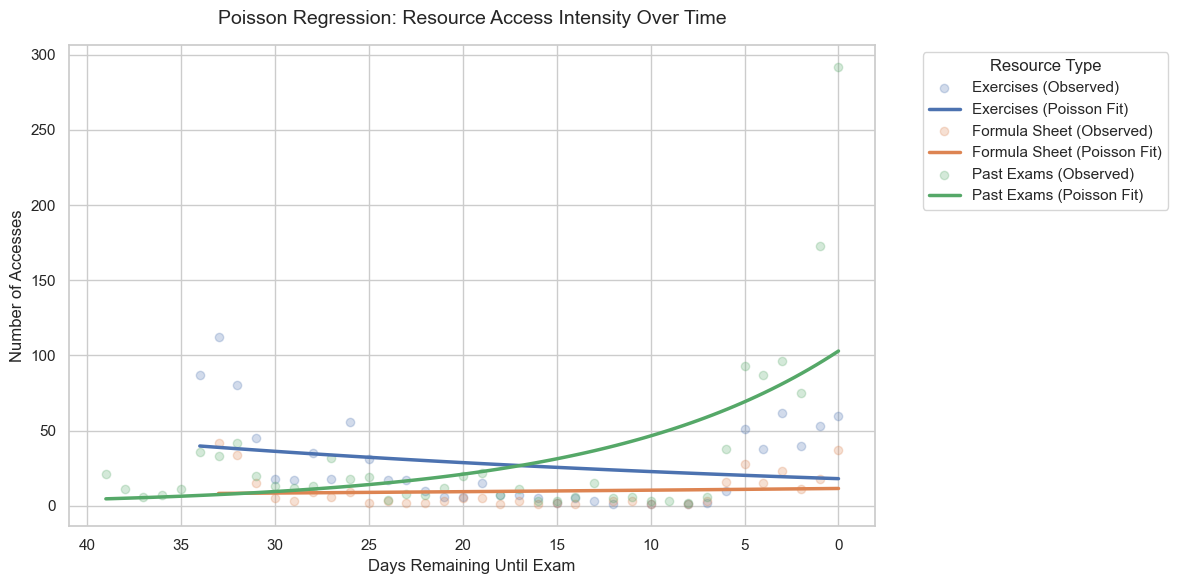

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf


sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

model_data = (
    df.groupby(["resource_type", "days_before_exam"], as_index=False)
      .size()
      .rename(columns={"size": "access_count"})
)

raw_types = model_data["resource_type"].unique()
colors = dict(zip(raw_types, sns.color_palette("deep", len(raw_types))))

for r_type in raw_types:
    subset = model_data[model_data["resource_type"] == r_type]
    
    # Clean label for the legend (e.g., 'past_exams' -> 'Past Exams')
    display_name = r_type.replace("_", " ").title()
    current_color = colors[r_type]
    
    # Plot actual data points (Scatter)
    plt.scatter(subset["days_before_exam"], subset["access_count"], 
                alpha=0.25, color=current_color, label=f"{display_name} (Observed)")
    
    # Fit Poisson regression
    model = smf.glm(formula="access_count ~ days_before_exam", 
                    data=subset, family=sm.families.Poisson()).fit()
    
    # Create prediction line
    x_range = np.linspace(subset["days_before_exam"].min(), subset["days_before_exam"].max(), 100)
    y_pred = model.predict(pd.DataFrame({"days_before_exam": x_range}))
    
    # Plot regression line with the same color
    plt.plot(x_range, y_pred, color=current_color, linewidth=2.5, label=f"{display_name} (Poisson Fit)")

# 3. Final Polish
plt.gca().invert_xaxis()
plt.title("Poisson Regression: Resource Access Intensity Over Time", fontsize=14, pad=15)
plt.xlabel("Days Remaining Until Exam", fontsize=12)
plt.ylabel("Number of Accesses", fontsize=12)

# Legend adjustment: Place it to the side so it doesn't block the data
plt.legend(title="Resource Type", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
plt.tight_layout()

plt.show()

test of non-independence (repeated clicks by the same student) issue

In [9]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

# Window setup
last_k = 7
total_days = (exam_date - academic_year_start).days + 1  # inclusive of day 0
recent_days = last_k + 1                                # days 0..7 -> 8 days
earlier_days = total_days - recent_days                 # days 8..40 -> 33 days
expected_prop = recent_days / total_days                # null proportion under uniform activity

df_test = df.copy()
df_test["in_last_7d"] = (df_test["days_before_exam"] <= last_k).astype(int)

# ==============================================================================
# 1. DESCRIPTIVE: How much of the data is repeat clicks by the same students?
# ==============================================================================
print("=== 1. REPEAT-CLICK CLUSTERING SUMMARY ===")
for r_type, grp in df_test.groupby("resource_type"):
    n_clicks = len(grp)
    n_students = grp["student"].nunique()
    repeat_clicks = n_clicks - n_students
    pct_repeat = (repeat_clicks / n_clicks) * 100
    max_by_one = grp["student"].value_counts().max()
    print(
        f"{r_type:15s} | Total clicks: {n_clicks:4d} | Unique students: {n_students:3d} | "
        f"Repeat clicks: {repeat_clicks:4d} ({pct_repeat:.1f}%) | Max by 1 student: {max_by_one}"
    )

# ==============================================================================
# 2. STUDENT-LEVEL PAIRED TEST (Controls for repeated clicks per student)
#    Compares each student's daily click rate in last 7 days vs. earlier days
# ==============================================================================
print("\n=== 2. STUDENT-LEVEL PAIRED RATE TEST (WILCOXON SIGNED-RANK) ===")
all_students_df = pd.DataFrame({"student": df_test["student"].unique()})

for r_type in df_test["resource_type"].unique():
    sub = df_test[df_test["resource_type"] == r_type]
    
    recent_counts = sub[sub["in_last_7d"] == 1].groupby("student").size()
    earlier_counts = sub[sub["in_last_7d"] == 0].groupby("student").size()
    
    paired = all_students_df.copy()
    paired["recent_rate"] = paired["student"].map(recent_counts).fillna(0) / recent_days
    paired["earlier_rate"] = paired["student"].map(earlier_counts).fillna(0) / earlier_days
    paired["diff"] = paired["recent_rate"] - paired["earlier_rate"]
    
    # Keep students who accessed this resource at least once
    active = paired[(paired["recent_rate"] + paired["earlier_rate"]) > 0]
    
    stat, p_val = stats.wilcoxon(active["recent_rate"], active["earlier_rate"], alternative="greater")
    pct_students_higher = (active["diff"] > 0).mean() * 100
    
    print(
        f"{r_type:15s} | Active students: {len(active):3d} | "
        f"Mean rate (Last 7d vs Earlier): {active['recent_rate'].mean():.3f} vs {active['earlier_rate'].mean():.3f} clicks/day | "
        f"Students with higher rate in last 7d: {pct_students_higher:.1f}% | "
        f"Wilcoxon p = {p_val:.4e}"
    )

# ==============================================================================
# 3. CLUSTER-ROBUST PROPORTION TEST (Direct fix to naive Binomial Test)
#    Tests if P(click in last 7 days) > expected_prop, clustering SEs by student
# ==============================================================================
print(f"\n=== 3. CLUSTER-ROBUST INTERCEPT TEST vs. UNIFORM NULL ({expected_prop:.1%}) ===")
null_logit = np.log(expected_prop / (1 - expected_prop))

for r_type in df_test["resource_type"].unique():
    sub = df_test[df_test["resource_type"] == r_type].copy()
    
    # Intercept-only logistic regression with standard errors clustered by student
    logit_mod = smf.logit("in_last_7d ~ 1", data=sub).fit(
        disp=False,
        cov_type="cluster",
        cov_kwds={"groups": sub["student"]}
    )
    
    est_logit = logit_mod.params["Intercept"]
    se_cluster = logit_mod.bse["Intercept"]
    z_stat = (est_logit - null_logit) / se_cluster
    p_val_one_sided = 1 - stats.norm.cdf(z_stat)
    obs_prop = sub["in_last_7d"].mean()
    
    print(
        f"{r_type:15s} | Observed share in last 7d: {obs_prop:.1%} (Null: {expected_prop:.1%}) | "
        f"Clustered z = {z_stat:.2f}, p = {p_val_one_sided:.4e}"
    )

=== 1. REPEAT-CLICK CLUSTERING SUMMARY ===
exercises       | Total clicks:  918 | Unique students: 175 | Repeat clicks:  743 (80.9%) | Max by 1 student: 23
formula_sheet   | Total clicks:  312 | Unique students: 154 | Repeat clicks:  158 (50.6%) | Max by 1 student: 6
past_exams      | Total clicks: 1291 | Unique students: 182 | Repeat clicks: 1109 (85.9%) | Max by 1 student: 46

=== 2. STUDENT-LEVEL PAIRED RATE TEST (WILCOXON SIGNED-RANK) ===
past_exams      | Active students: 182 | Mean rate (Last 7d vs Earlier): 0.591 vs 0.072 clicks/day | Students with higher rate in last 7d: 90.1% | Wilcoxon p = 4.3205e-30
exercises       | Active students: 175 | Mean rate (Last 7d vs Earlier): 0.226 vs 0.104 clicks/day | Students with higher rate in last 7d: 56.6% | Wilcoxon p = 1.1307e-07
formula_sheet   | Active students: 154 | Mean rate (Last 7d vs Earlier): 0.123 vs 0.032 clicks/day | Students with higher rate in last 7d: 69.5% | Wilcoxon p = 3.0191e-17

=== 3. CLUSTER-ROBUST INTERCEPT TEST vs

In [10]:
import numpy as np
import pandas as pd
from scipy import stats

# 1. Prepare data: Count accesses per day and per resource type
daily_counts_res = df.groupby(["days_before_exam", "resource_type"]).size().reset_index(name="access_count")

results = []

print(f"{'Resource Type':<18} | {'Spearman Rho':<12} | {'p-val (Corr)':<12} | {'Binom p-val':<12} | {'Result'}")
print("-" * 80)

for r_type in df["resource_type"].unique():
    # Filter for this specific resource
    subset = daily_counts_res[daily_counts_res["resource_type"] == r_type]
    
    # Resource-specific observation window (e.g., ~34 for exercises, ~33 for formula_sheet)
    max_day_r = int(subset["days_before_exam"].max())
    total_days_r = max_day_r + 1  # inclusive of day 0
    
    # Ensure we have data for this resource's active range (fill zeros for missing days within active window)
    full_range = pd.DataFrame({"days_before_exam": range(total_days_r)})
    subset = pd.merge(full_range, subset, on="days_before_exam", how="left").fillna({"access_count": 0})
    
    # --- Spearman Correlation ---
    # Testing the trend: as days decrease, do accesses increase?
    rho, p_corr = stats.spearmanr(subset["days_before_exam"], subset["access_count"])
    
    # --- Binomial Test ---
    # Testing concentration: is the final week significantly busier than expected
    # relative to this resource's actual availability window?
    k = int(subset[subset["days_before_exam"] < 7]["access_count"].sum())  # days 0..6 (7 days)
    n = int(subset["access_count"].sum())
    prob_success_null = min(7, total_days_r) / total_days_r
    
    # Avoid errors if a resource has 0 total accesses
    if n > 0:
        res_binom = stats.binomtest(k, n=n, p=prob_success_null, alternative='greater')
        p_binom = res_binom.pvalue
    else:
        p_binom = np.nan

    # Determine significance label
    status = "Significant" if p_binom < 0.05 and p_corr < 0.05 else "Not Sig."
    
    print(f"{r_type:<18} | {rho:>12.3f} | {p_corr:>12.2e} | {p_binom:>12.2e} | {status}")

Resource Type      | Spearman Rho | p-val (Corr) | Binom p-val  | Result
--------------------------------------------------------------------------------
past_exams         |       -0.101 |     5.36e-01 |     0.00e+00 | Not Sig.
exercises          |        0.278 |     1.06e-01 |     6.64e-24 | Not Sig.
formula_sheet      |       -0.007 |     9.68e-01 |     3.47e-26 | Not Sig.


In [11]:
# Calculate the average timing for each resource
mean_days = df.groupby("resource_type")["days_before_exam"].mean().reset_index()
mean_days.columns = ["Resource Type", "Avg Days Before Exam"]

# Calculate what percentage of total clicks happened in the last 48 hours
last_2_days = df[df["days_before_exam"] <= 2].groupby("resource_type").size()
total_clicks = df.groupby("resource_type").size()
cramming_ratio = (last_2_days / total_clicks * 100).reset_index()
cramming_ratio.columns = ["Resource Type", "% Clicks in Last 48h"]

# Merge and display
summary_stats = pd.merge(mean_days, cramming_ratio, on="Resource Type")
print(summary_stats.sort_values(by="Avg Days Before Exam"))

   Resource Type  Avg Days Before Exam  % Clicks in Last 48h
2     past_exams             10.351665             41.828040
1  formula_sheet             15.820513             21.153846
0      exercises             19.807190             16.666667


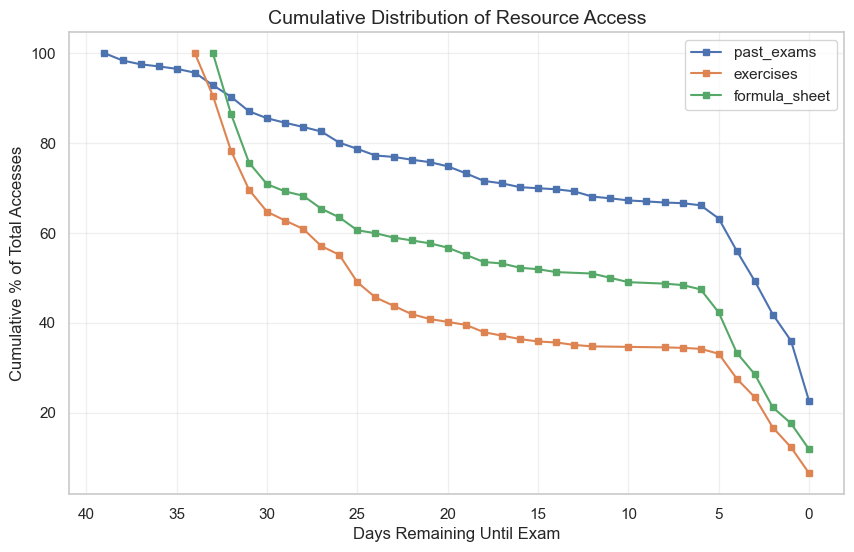

In [12]:
plt.figure(figsize=(10, 6))

# Sort to ensure cumulative sum works correctly
df_sorted = df.sort_values("days_before_exam", ascending=False)

for r_type in df["resource_type"].unique():
    subset = df_sorted[df_sorted["resource_type"] == r_type]
    # Calculate cumulative percentage of logs
    counts = subset.groupby("days_before_exam").size().cumsum()
    total = subset.shape[0]
    plt.plot(counts.index, (counts / total) * 100, label=r_type, marker='s', markersize=4)

plt.gca().invert_xaxis()
plt.title("Cumulative Distribution of Resource Access", fontsize=14)
plt.xlabel("Days Remaining Until Exam")
plt.ylabel("Cumulative % of Total Accesses")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Prepare daily counts per resource type
grouped = df.groupby(["days_before_exam", "resource_type"]).size().reset_index(name="access_count")

print("--- Poisson Regression Results (GLM) ---")
for r_type in grouped["resource_type"].unique():
    raw_sub = grouped[grouped["resource_type"] == r_type]
    
    # Active window for this resource: 0 .. first day observed (e.g., ~34 for exercises, ~33 for formula_sheet)
    max_day_r = int(raw_sub["days_before_exam"].max())
    full_range = pd.DataFrame({"days_before_exam": range(max_day_r + 1)})
    subset = pd.merge(full_range, raw_sub, on="days_before_exam", how="left").fillna({"access_count": 0})
    
    # Fit the model: access_count ~ days_before_exam
    # Negative coefficient means counts increase as days_before_exam decreases (closer to exam)
    model = smf.glm(
        formula="access_count ~ days_before_exam",
        data=subset,
        family=sm.families.Poisson()
    ).fit()
    
    coeff = model.params["days_before_exam"]
    p_val = model.pvalues["days_before_exam"]
    
    # Incident Rate Ratio (IRR) per 1-day increase in days_before_exam; (1/irr)-1 is per 1-day closer to exam
    irr = np.exp(coeff)
    
    print(f"\nResource: {r_type} (active window: Days {max_day_r}..0)")
    print(f"  Coefficient (Beta): {coeff:.4f} (p={p_val:.4e})")
    print(f"  Incident Rate Ratio (IRR): {irr:.4f}")
    print(f"  Interpretation: For every 1 day closer to the exam, accesses change by {((1/irr)-1)*100:.1f}%")

--- Poisson Regression Results (GLM) ---

Resource: exercises (active window: Days 34..0)
  Coefficient (Beta): 0.0280 (p=6.5207e-17)
  Incident Rate Ratio (IRR): 1.0284
  Interpretation: For every 1 day closer to the exam, accesses change by -2.8%

Resource: formula_sheet (active window: Days 33..0)
  Coefficient (Beta): -0.0071 (p=2.2141e-01)
  Incident Rate Ratio (IRR): 0.9930
  Interpretation: For every 1 day closer to the exam, accesses change by 0.7%

Resource: past_exams (active window: Days 39..0)
  Coefficient (Beta): -0.0795 (p=4.8719e-154)
  Incident Rate Ratio (IRR): 0.9236
  Interpretation: For every 1 day closer to the exam, accesses change by 8.3%


<>:53: SyntaxWarning: invalid escape sequence '\h'
<>:53: SyntaxWarning: invalid escape sequence '\h'
C:\Users\borbr\AppData\Local\Temp\ipykernel_15616\1448290529.py:53: SyntaxWarning: invalid escape sequence '\h'
  plt.xlabel("Predicted Access Intensity ($\hat{y}$)", fontsize=12)


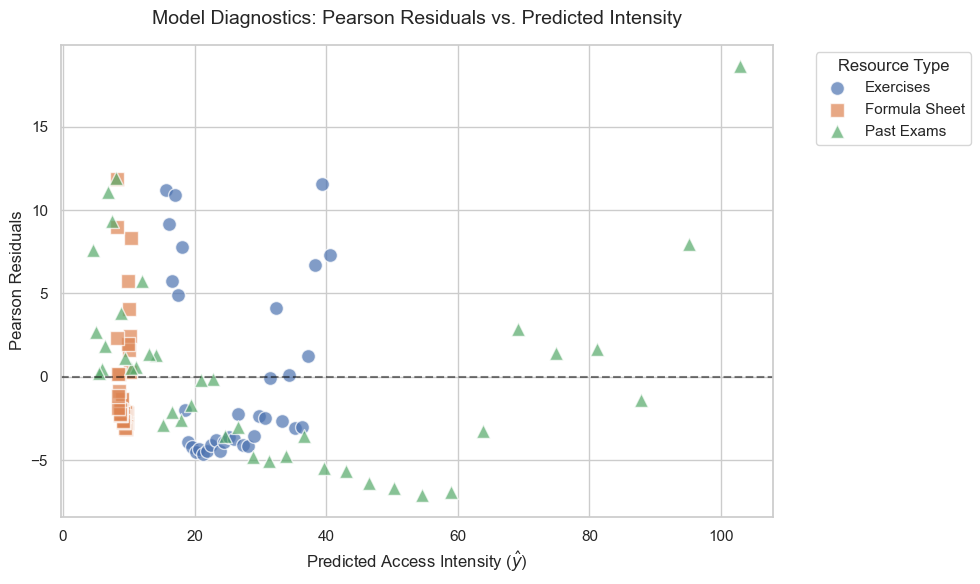

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 1. Setup the style to match the "natural" Seaborn look
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Prepare data
grouped = df.groupby(["days_before_exam", "resource_type"]).size().reset_index(name="access_count")

# 2. Dynamically assign natural hues and markers
unique_types = grouped["resource_type"].unique()
# "deep" is the default Seaborn palette that gives those natural colors
palette = sns.color_palette("deep", len(unique_types))
colors = dict(zip(unique_types, palette))
markers = dict(zip(unique_types, ['o', 's', '^', 'D', 'v'][:len(unique_types)]))

for r_type in unique_types:
    raw_sub = grouped[grouped["resource_type"] == r_type]
    
    # Fill missing days (0 accesses) strictly within this resource's active availability window
    max_day_r = int(raw_sub["days_before_exam"].max())
    full_range = pd.DataFrame({"days_before_exam": range(max_day_r + 1)})
    subset = pd.merge(full_range, raw_sub, on="days_before_exam", how="left").fillna({"access_count": 0})
    
    # Format the label for the legend (e.g., past_exams -> Past Exams)
    display_name = r_type.replace("_", " ").title()
    
    # Fit the Poisson GLM
    model = smf.glm(formula="access_count ~ days_before_exam", 
                    data=subset, 
                    family=sm.families.Poisson()).fit()
    
    predicted = model.predict(subset)
    # Pearson residuals check for overdispersion
    residuals = model.resid_pearson 

    # Use the natural color and cleaned-up name
    plt.scatter(predicted, residuals, 
                color=colors[r_type], 
                label=display_name, 
                alpha=0.7, 
                edgecolors='w', 
                s=100, 
                marker=markers[r_type])

# 3. Aesthetics for Manuscript
plt.axhline(0, color='black', linestyle='--', linewidth=1.5, alpha=0.5)
plt.title("Model Diagnostics: Pearson Residuals vs. Predicted Intensity", fontsize=14, pad=15)
plt.xlabel("Predicted Access Intensity ($\hat{y}$)", fontsize=12)
plt.ylabel("Pearson Residuals", fontsize=12)

# Legend adjustment
plt.legend(title="Resource Type", frameon=True, shadow=False, bbox_to_anchor=(1.05, 1), loc='upper left')

# Save and Show
plt.tight_layout()
plt.savefig("poisson_diagnostic_plot.png", dpi=300)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

grouped = df.groupby(["days_before_exam", "resource_type"]).size().reset_index(name="access_count")

for r_type in grouped["resource_type"].unique():
    raw_sub = grouped[grouped["resource_type"] == r_type]
    
    # Active window for this resource (Days 0 .. max_day_r)
    max_day_r = int(raw_sub["days_before_exam"].max())
    full_range = pd.DataFrame({"days_before_exam": range(max_day_r + 1)})
    subset = pd.merge(full_range, raw_sub, on="days_before_exam", how="left").fillna({"access_count": 0})
    
    model = smf.glm(
        formula="access_count ~ days_before_exam",
        data=subset,
        family=sm.families.Poisson()
    ).fit()
    
    # 1. Calculate Pearson Chi-Square Statistic
    pearson_chi2 = np.sum(model.resid_pearson**2)
    df_residual = model.df_resid  # Degrees of freedom
    
    # 2. Calculate the Dispersion Ratio (Should be close to 1.0)
    dispersion_ratio = pearson_chi2 / df_residual
    
    # 3. Calculate p-value for Goodness-of-Fit
    p_value = 1 - stats.chi2.cdf(pearson_chi2, df_residual)

    print(f"Resource: {r_type} (active window: Days {max_day_r}..0)")
    print(f"  Pearson Chi2: {pearson_chi2:.2f}")
    print(f"  Dispersion Ratio: {dispersion_ratio:.2f}")
    print(f"  P-value (Goodness of Fit): {p_value:.4f}\n")

Resource: exercises (active window: Days 34..0)
  Pearson Chi2: 996.23
  Dispersion Ratio: 30.19
  P-value (Goodness of Fit): 0.0000

Resource: formula_sheet (active window: Days 33..0)
  Pearson Chi2: 470.48
  Dispersion Ratio: 14.70
  P-value (Goodness of Fit): 0.0000

Resource: past_exams (active window: Days 39..0)
  Pearson Chi2: 1283.95
  Dispersion Ratio: 33.79
  P-value (Goodness of Fit): 0.0000



In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

grouped = df.groupby(["days_before_exam", "resource_type"]).size().reset_index(name="access_count")

# Change the family from Poisson to NegativeBinomial
for r_type in grouped["resource_type"].unique():
    raw_sub = grouped[grouped["resource_type"] == r_type]
    
    # Active window for this resource (Days 0 .. max_day_r)
    max_day_r = int(raw_sub["days_before_exam"].max())
    full_range = pd.DataFrame({"days_before_exam": range(max_day_r + 1)})
    subset = pd.merge(full_range, raw_sub, on="days_before_exam", how="left").fillna({"access_count": 0}).copy()
    
    # Switch to Negative Binomial to handle overdispersion
    model = smf.glm(
        formula="access_count ~ days_before_exam",
        data=subset,
        family=sm.families.NegativeBinomial()
    ).fit()
    
    # Now check diagnostics again
    pearson_chi2 = np.sum(model.resid_pearson**2)
    dispersion_ratio = pearson_chi2 / model.df_resid
    print(f"{r_type} (active window: Days {max_day_r}..0) Dispersion: {dispersion_ratio:.2f}")

exercises (active window: Days 34..0) Dispersion: 1.12
formula_sheet (active window: Days 33..0) Dispersion: 1.45
past_exams (active window: Days 39..0) Dispersion: 0.98


c:\Users\borbr\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\genmod\families\family.py:1367: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  warnings.warn("Negative binomial dispersion parameter alpha not "
c:\Users\borbr\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\genmod\families\family.py:1367: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  warnings.warn("Negative binomial dispersion parameter alpha not "
c:\Users\borbr\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\genmod\families\family.py:1367: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  warnings.warn("Negative binomial dispersion parameter alpha not "
